In [2]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()
events = pd.read_csv(PROJECT_ROOT / "events.csv")

print("Данные загружены:", events.shape)

Данные загружены: (2756101, 5)


In [3]:
from pathlib import Path

print("Текущая папка:", Path.cwd())
print("Содержимое папки:")
print(list(Path.cwd().iterdir()))

Текущая папка: /home/iu31101987/mlops-final/ecom_raw_start-main
Содержимое папки:
[PosixPath('/home/iu31101987/mlops-final/ecom_raw_start-main/.venv'), PosixPath('/home/iu31101987/mlops-final/ecom_raw_start-main/ranker.pkl'), PosixPath('/home/iu31101987/mlops-final/ecom_raw_start-main/requirements.txt'), PosixPath('/home/iu31101987/mlops-final/ecom_raw_start-main/pyproject.toml'), PosixPath('/home/iu31101987/mlops-final/ecom_raw_start-main/item_properties_part1.csv'), PosixPath('/home/iu31101987/mlops-final/ecom_raw_start-main/notebooks'), PosixPath('/home/iu31101987/mlops-final/ecom_raw_start-main/item_properties_part2.csv'), PosixPath('/home/iu31101987/mlops-final/ecom_raw_start-main/loaded_models.py'), PosixPath('/home/iu31101987/mlops-final/ecom_raw_start-main/main.py'), PosixPath('/home/iu31101987/mlops-final/ecom_raw_start-main/train_model_original.py'), PosixPath('/home/iu31101987/mlops-final/ecom_raw_start-main/data_for_training.parquet'), PosixPath('/home/iu31101987/mlops-fina

In [4]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()

events_path = PROJECT_ROOT / "events.csv"

print("Файл найден:", events_path.exists())

events = pd.read_csv(events_path)

print("Размер данных:", events.shape)
display(events.head())

Файл найден: True
Размер данных: (2756101, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [5]:
# Количество событий каждого типа
event_counts = events["event"].value_counts()

# Доля каждого типа событий
event_percent = (
    events["event"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

event_summary = pd.DataFrame({
    "Количество": event_counts,
    "Доля, %": event_percent,
})

display(event_summary)

# Пропуски в данных
print("\nПропуски по столбцам:")
display(events.isna().sum())

,Количество,"Доля, %"
event,,
view,2664312,96.67
addtocart,69332,2.52
transaction,22457,0.81



Пропуски по столбцам:


timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64

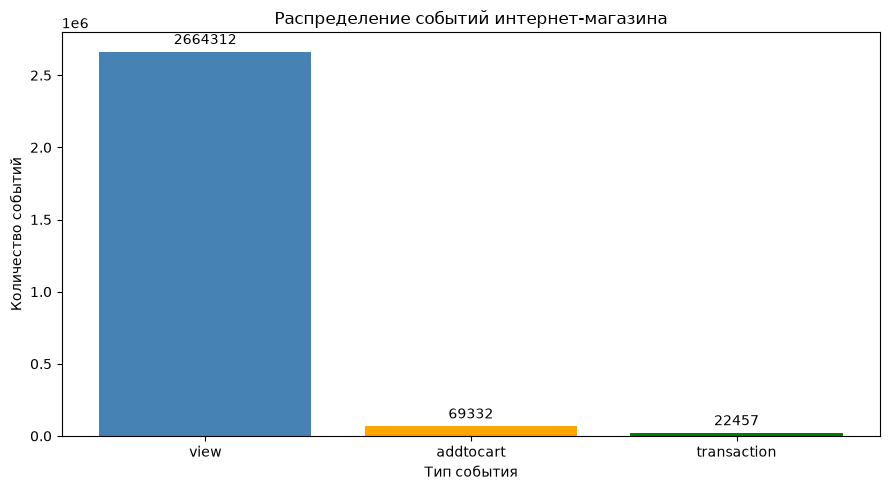

In [6]:
import matplotlib.pyplot as plt

event_counts = events["event"].value_counts()

plt.figure(figsize=(9, 5))

bars = plt.bar(
    event_counts.index,
    event_counts.values,
    color=["steelblue", "orange", "green"]
)

plt.title("Распределение событий интернет-магазина")
plt.xlabel("Тип события")
plt.ylabel("Количество событий")

plt.bar_label(bars, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

In [7]:
# Преобразуем Unix timestamp из миллисекунд в дату
events["event_time"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    utc=True
)

print("Начало данных:", events["event_time"].min())
print("Конец данных:", events["event_time"].max())

print("\nКоличество уникальных пользователей:",
      events["visitorid"].nunique())

print("Количество уникальных товаров:",
      events["itemid"].nunique())

print("\nПериод данных в днях:",
      (events["event_time"].max() - events["event_time"].min()).days)

Начало данных: 2015-05-03 03:00:04.384000+00:00
Конец данных: 2015-09-18 02:59:47.788000+00:00

Количество уникальных пользователей: 1407580
Количество уникальных товаров: 235061

Период данных в днях: 137


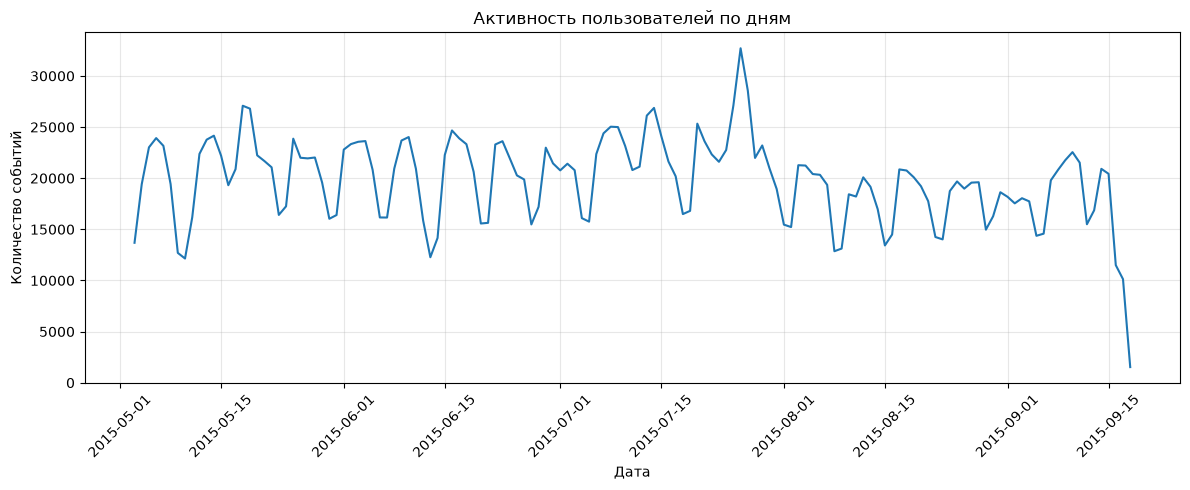

Среднее количество событий в день: 19828
Максимум событий в день: 32703
Минимум событий в день: 1528


In [8]:
# Количество событий по дням
daily_events = (
    events
    .set_index("event_time")
    .resample("D")
    .size()
)

plt.figure(figsize=(12, 5))

plt.plot(
    daily_events.index,
    daily_events.values,
    linewidth=1.5
)

plt.title("Активность пользователей по дням")
plt.xlabel("Дата")
plt.ylabel("Количество событий")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

print("Среднее количество событий в день:", round(daily_events.mean()))
print("Максимум событий в день:", daily_events.max())
print("Минимум событий в день:", daily_events.min())

event,addtocart,transaction,view
event_time,,,
2015-05-03 00:00:00+00:00,296,83,13304
2015-05-04 00:00:00+00:00,579,154,18681
2015-05-05 00:00:00+00:00,565,225,22225
2015-05-06 00:00:00+00:00,647,258,23015
2015-05-07 00:00:00+00:00,578,217,22369


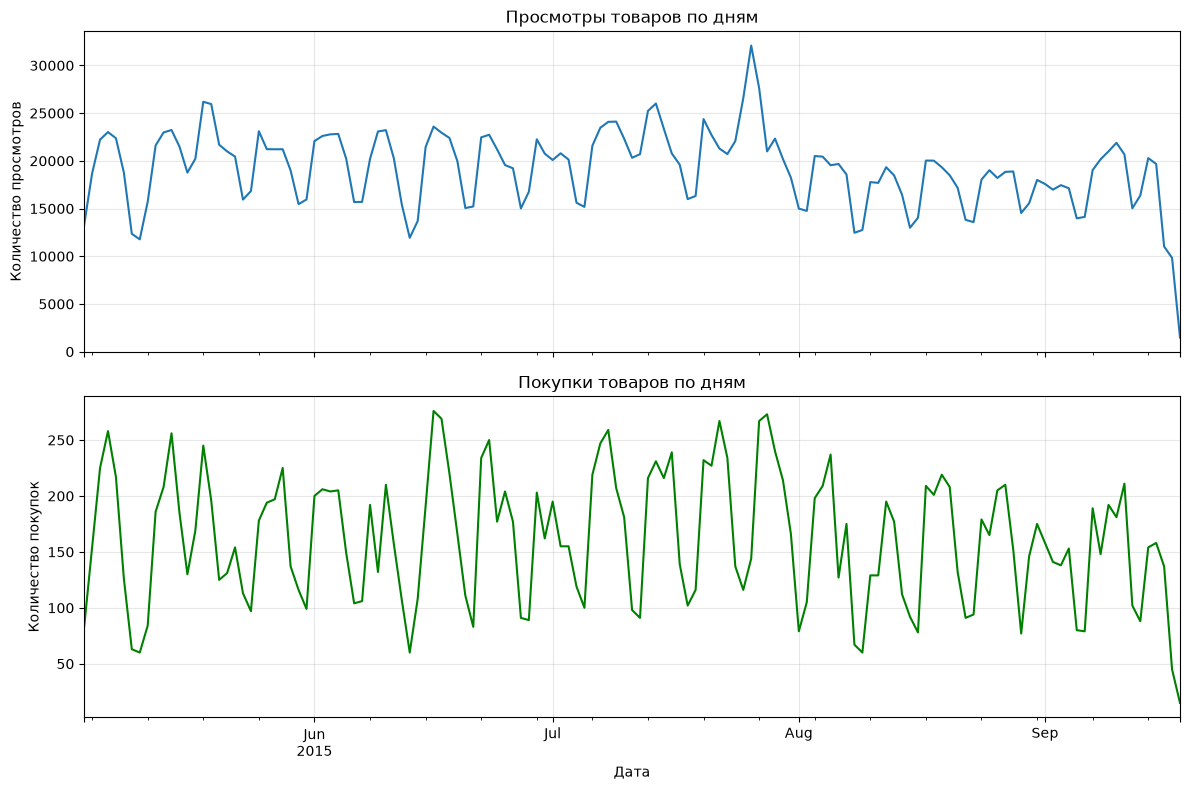

Среднее количество покупок в день: 161.56
Максимум покупок в день: 276


In [9]:
# Количество событий каждого типа по дням
daily_by_event = (
    events
    .groupby([
        pd.Grouper(key="event_time", freq="D"),
        "event"
    ])
    .size()
    .unstack(fill_value=0)
)

display(daily_by_event.head())

# Строим графики просмотров и покупок
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

daily_by_event["view"].plot(
    ax=axes[0],
    title="Просмотры товаров по дням"
)
axes[0].set_ylabel("Количество просмотров")
axes[0].grid(alpha=0.3)

daily_by_event["transaction"].plot(
    ax=axes[1],
    color="green",
    title="Покупки товаров по дням"
)
axes[1].set_ylabel("Количество покупок")
axes[1].set_xlabel("Дата")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(
    "Среднее количество покупок в день:",
    round(daily_by_event["transaction"].mean(), 2)
)

print(
    "Максимум покупок в день:",
    daily_by_event["transaction"].max()
)

In [10]:
# Загружаем дерево категорий
categories = pd.read_csv(PROJECT_ROOT / "category_tree.csv")

print("Размер таблицы:", categories.shape)

print("\nТипы данных:")
print(categories.dtypes)

print("\nПропуски:")
print(categories.isna().sum())

print("\nПервые 10 строк:")
display(categories.head(10))

print(
    "\nКоличество уникальных категорий:",
    categories["categoryid"].nunique()
)

Размер таблицы: (1669, 2)

Типы данных:
categoryid      int64
parentid      float64
dtype: object

Пропуски:
categoryid     0
parentid      25
dtype: int64

Первые 10 строк:


,categoryid,parentid
0,1016,213.0
1,809,169.0
2,570,9.0
3,1691,885.0
4,536,1691.0
5,231,NaN
6,542,378.0
7,1146,542.0
8,1140,542.0
9,1479,1537.0



Количество уникальных категорий: 1669


In [11]:
# Проверяем ссылки на родительские категории
category_ids = set(categories["categoryid"])

parent_ids = set(
    categories["parentid"].dropna().astype(int)
)

missing_parents = parent_ids - category_ids

print("Корневых категорий:", categories["parentid"].isna().sum())
print("Уникальных родительских категорий:", len(parent_ids))
print("Отсутствующих родительских категорий:", len(missing_parents))

if missing_parents:
    print("Примеры отсутствующих родителей:", sorted(missing_parents)[:10])
else:
    print("Все родительские категории найдены!")

Корневых категорий: 25
Уникальных родительских категорий: 362
Отсутствующих родительских категорий: 0
Все родительские категории найдены!


In [12]:
# Загружаем свойства товаров из двух файлов
properties_1 = pd.read_csv(
    PROJECT_ROOT / "item_properties_part1.csv"
)

properties_2 = pd.read_csv(
    PROJECT_ROOT / "item_properties_part2.csv"
)

print("Первый файл:", properties_1.shape)
print("Второй файл:", properties_2.shape)

print("\nТипы данных:")
print(properties_1.dtypes)

print("\nПервые 10 строк:")
display(properties_1.head(10))

print("\nКоличество уникальных свойств:")
print(properties_1["property"].nunique())

print("\nСамые частые свойства:")
display(properties_1["property"].value_counts().head(10))

Первый файл: (10999999, 4)
Второй файл: (9275903, 4)

Типы данных:
timestamp     int64
itemid        int64
property     object
value        object
dtype: object

Первые 10 строк:


,timestamp,itemid,property,value
0,1435460400000,460429,categoryid,1338
1,1441508400000,206783,888,1116713 960601 n277.200
2,1439089200000,395014,400,n552.000 639502 n720.000 424566
3,1431226800000,59481,790,n15360.000
4,1431831600000,156781,917,828513
5,1436065200000,285026,available,0
6,1434250800000,89534,213,1121373
7,1431831600000,264312,6,319724
8,1433646000000,229370,202,1330310
9,1434250800000,98113,451,1141052 n48.000



Количество уникальных свойств:
1097

Самые частые свойства:


property
888           1629817
790            970800
available      817387
categoryid     426305
6              343207
283            323681
776            311654
678            261829
364            256340
202            242984
Name: count, dtype: int64

In [13]:
# Выбираем только свойства, необходимые для модели
important_properties = ["categoryid", "available"]

props_1 = properties_1.loc[
    properties_1["property"].isin(important_properties)
].copy()

props_2 = properties_2.loc[
    properties_2["property"].isin(important_properties)
].copy()

# Объединяем отфильтрованные данные
item_props = pd.concat(
    [props_1, props_2],
    ignore_index=True
)

# Преобразуем временные метки
item_props["event_time"] = pd.to_datetime(
    item_props["timestamp"],
    unit="ms",
    utc=True
)

print("Количество записей:", len(item_props))

print("\nРаспределение свойств:")
display(item_props["property"].value_counts())

print("\nУникальных товаров:", item_props["itemid"].nunique())

print("\nПримеры записей:")
display(item_props.head(10))

Количество записей: 2291853

Распределение свойств:


property
available     1503639
categoryid     788214
Name: count, dtype: int64


Уникальных товаров: 417053

Примеры записей:


,timestamp,itemid,property,value,event_time
0,1435460400000,460429,categoryid,1338,2015-06-28 03:00:00+00:00
1,1436065200000,285026,available,0,2015-07-05 03:00:00+00:00
2,1437274800000,186518,available,0,2015-07-19 03:00:00+00:00
3,1433646000000,423682,available,0,2015-06-07 03:00:00+00:00
4,1434250800000,316253,available,1,2015-06-14 03:00:00+00:00
5,1437274800000,430459,available,0,2015-07-19 03:00:00+00:00
6,1433041200000,411262,available,0,2015-05-31 03:00:00+00:00
7,1441508400000,50372,available,0,2015-09-06 03:00:00+00:00
8,1441508400000,289043,available,0,2015-09-06 03:00:00+00:00
9,1435460400000,365407,available,0,2015-06-28 03:00:00+00:00


In [14]:
# Оставляем только записи о доступности
availability = item_props.loc[
    item_props["property"] == "available",
    ["itemid", "timestamp", "value"]
].copy()

# Преобразуем значения в числа
availability["value"] = pd.to_numeric(
    availability["value"],
    errors="coerce"
)

print("Распределение значений available:")
display(availability["value"].value_counts(dropna=False))

# Считаем количество различных состояний у каждого товара
unique_states = availability.groupby("itemid")["value"].nunique()

print("\nТоваров с данными о доступности:", len(unique_states))

print(
    "Товаров с разными значениями available:",
    (unique_states > 1).sum()
)

print(
    "Доля товаров с разными значениями, %:",
    round((unique_states > 1).mean() * 100, 2)
)

Распределение значений available:


value
0    863086
1    640553
Name: count, dtype: int64


Товаров с данными о доступности: 417053
Товаров с разными значениями available: 67001
Доля товаров с разными значениями, %: 16.07


In [15]:
# Товары, встречающиеся в событиях
event_items = set(events["itemid"].unique())

# Товары с информацией о категории
category_items = set(
    item_props.loc[
        item_props["property"] == "categoryid",
        "itemid"
    ]
)

# Товары с информацией о доступности
available_items = set(
    item_props.loc[
        item_props["property"] == "available",
        "itemid"
    ]
)

print("Товаров в событиях:", len(event_items))

print(
    "Товаров с категорией:",
    len(event_items & category_items)
)

print(
    "Покрытие категориями, %:",
    round(len(event_items & category_items) / len(event_items) * 100, 2)
)

print(
    "Товаров с доступностью:",
    len(event_items & available_items)
)

print(
    "Покрытие доступностью, %:",
    round(len(event_items & available_items) / len(event_items) * 100, 2)
)

Товаров в событиях: 235061
Товаров с категорией: 185246
Покрытие категориями, %: 78.81
Товаров с доступностью: 185246
Покрытие доступностью, %: 78.81


In [16]:
print("Дубликаты событий:", events.duplicated().sum())

print(
    "Дубликаты записей о свойствах:",
    item_props.duplicated(
        subset=["timestamp", "itemid", "property", "value"]
    ).sum()
)

print("\nПериод событий:")
print(events["event_time"].min())
print(events["event_time"].max())

print("\nПериод свойств:")
print(item_props["event_time"].min())
print(item_props["event_time"].max())

print("\nПропуски в важных свойствах:")
print(item_props[["timestamp", "itemid", "property", "value"]].isna().sum())

Дубликаты событий: 460
Дубликаты записей о свойствах: 0

Период событий:
2015-05-03 03:00:04.384000+00:00
2015-09-18 02:59:47.788000+00:00

Период свойств:
2015-05-10 03:00:00+00:00
2015-09-13 03:00:00+00:00

Пропуски в важных свойствах:
timestamp    0
itemid       0
property     0
value        0
dtype: int64


In [17]:
# Выбираем повторяющиеся строки
duplicates = events.loc[
    events.duplicated(
        subset=[
            "timestamp",
            "visitorid",
            "event",
            "itemid",
            "transactionid"
        ],
        keep="first"
    )
]

print("Количество дубликатов:", len(duplicates))

print("\nДубликаты по типам событий:")
display(duplicates["event"].value_counts())

print("\nПримеры дубликатов:")
display(duplicates.head(10))

Количество дубликатов: 460

Дубликаты по типам событий:


event
addtocart    366
view          94
Name: count, dtype: int64


Примеры дубликатов:


,timestamp,visitorid,event,itemid,transactionid,event_time
22404,1433180781440,1045411,addtocart,379647,NaN,2015-06-01 17:46:21.440000+00:00
34465,1433274223925,366538,addtocart,252068,NaN,2015-06-02 19:43:43.925000+00:00
39738,1433265100661,198153,addtocart,48715,NaN,2015-06-02 17:11:40.661000+00:00
41774,1433270868154,1268755,view,60980,NaN,2015-06-02 18:47:48.154000+00:00
42469,1433277134682,555487,addtocart,397642,NaN,2015-06-02 20:32:14.682000+00:00
75063,1433463640728,497546,addtocart,278319,NaN,2015-06-05 00:20:40.728000+00:00
87304,1433463912411,263168,addtocart,436219,NaN,2015-06-05 00:25:12.411000+00:00
89928,1433475871737,1159733,addtocart,104116,NaN,2015-06-05 03:44:31.737000+00:00
103932,1433549575965,952199,addtocart,61273,NaN,2015-06-06 00:12:55.965000+00:00
122521,1433634301251,612160,addtocart,258266,NaN,2015-06-06 23:45:01.251000+00:00


In [18]:
event_columns = [
    "timestamp",
    "visitorid",
    "event",
    "itemid",
    "transactionid"
]

# Удаляем только точные дубликаты исходных событий
events_clean = events.drop_duplicates(
    subset=event_columns,
    keep="first"
).copy()

print("Исходных событий:", len(events))
print("После очистки:", len(events_clean))
print("Удалено дубликатов:", len(events) - len(events_clean))

print("\nРаспределение событий после очистки:")
display(events_clean["event"].value_counts())

print("\nКоличество покупок до очистки:",
      (events["event"] == "transaction").sum())

print("Количество покупок после очистки:",
      (events_clean["event"] == "transaction").sum())

Исходных событий: 2756101
После очистки: 2755641
Удалено дубликатов: 460

Распределение событий после очистки:


event
view           2664218
addtocart        68966
transaction      22457
Name: count, dtype: int64


Количество покупок до очистки: 22457
Количество покупок после очистки: 22457
